# Load and display MRC templates

Run the cells in order using the project’s `.venv` Python kernel.


## 1. Preparation

If dependencies are missing, run the optional installation cell first.


In [ ]:
# Uncomment to install dependencies into the active notebook kernel.
# %pip install mrcfile numpy matplotlib


In [5]:
from pathlib import Path

import mrcfile
import numpy as np
import matplotlib.pyplot as plt

# Find the data folder from either the project root or LatentSpace folder.
working_directory = Path.cwd().resolve()
project_root = next(
    (folder for folder in (working_directory, *working_directory.parents)
     if (folder / "LatentSpace_data").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Cannot find LatentSpace_data in the current folder or its parents.")

mrc_path = (
    project_root / "LatentSpace_data" / "cryosparc_P543_templates_selected.mrc"
)


## 2. Functions

Load MRC data and display images or slices in a grayscale gallery.


In [15]:
def read_mrc(file_path: str | Path) -> np.ndarray:
    """Load MRC data into a NumPy array, preserving its stored axis order."""
    with mrcfile.open(str(file_path), mode="r") as mrc:
        # Copy so the array remains usable after the file is closed.
        return mrc.data.copy()


def display_mrc(data: np.ndarray, image_names=None) -> None:
    """Display a 2D image or a gallery of slices from a 3D MRC array."""
    if data.ndim == 2:
        images = data[np.newaxis, ...]
    elif data.ndim == 3:
        images = data
    else:
        raise ValueError(f"Expected 2D or 3D MRC data, got shape {data.shape}")

    count = len(images)
    if image_names is not None and len(image_names) != count:
        raise ValueError("Provide one image name for each image")
    columns = min(5, count)
    rows = (count + columns - 1) // columns
    fig, axes = plt.subplots(
        rows, columns, figsize=(3 * columns, 3 * rows), squeeze=False
    )
    for index, ax in enumerate(axes.flat):
        if index < count:
            ax.imshow(images[index], cmap="gray", origin="upper")
            title = (str(image_names[index]).replace("@", "@\n", 1)
                     if image_names is not None else f"Image / slice {index + 1}")
            ax.set_title(title, fontsize=8)
        ax.axis("off")
    fig.suptitle("MRC images / slices")
    fig.tight_layout()
    plt.show()


## 3. Execution

Read the selected cryoSPARC templates, inspect their dimensions, and display them.


In [ ]:
data = read_mrc(mrc_path)
print(f"Loaded: {mrc_path}")
print(f"Shape: {data.shape}")
print(f"Data type: {data.dtype}")
display_mrc(data)


## 4. Load only 50 images from a large MRC stack

Run the preparation and function cells above first. This reads the first 50 images using memory mapping, so the full stack is not copied into RAM. Change `large_mrc_path` below to use another file. This treats the first axis as separate images, rather than a 3D volume.


In [13]:
def read_first_mrc_images(file_path: str | Path, count: int = 50) -> np.ndarray:
    """Copy only the first count images from a memory-mapped MRC stack."""
    if count < 1:
        raise ValueError("count must be at least 1")

    with mrcfile.mmap(str(file_path), mode="r") as mrc:
        if mrc.data.ndim != 3:
            raise ValueError(f"Expected an image stack, got shape {mrc.data.shape}")
        total_images = mrc.data.shape[0]
        selected_count = min(count, total_images)
        images = mrc.data[:selected_count].copy()

    print(f"Loaded {selected_count} of {total_images} images")
    print(f"Subset memory: {images.nbytes / 1024**2:.1f} MiB")
    return images


Loaded 50 of 57107 images
Subset memory: 6.2 MiB
Shape: (50, 256, 256)
Data type: float16


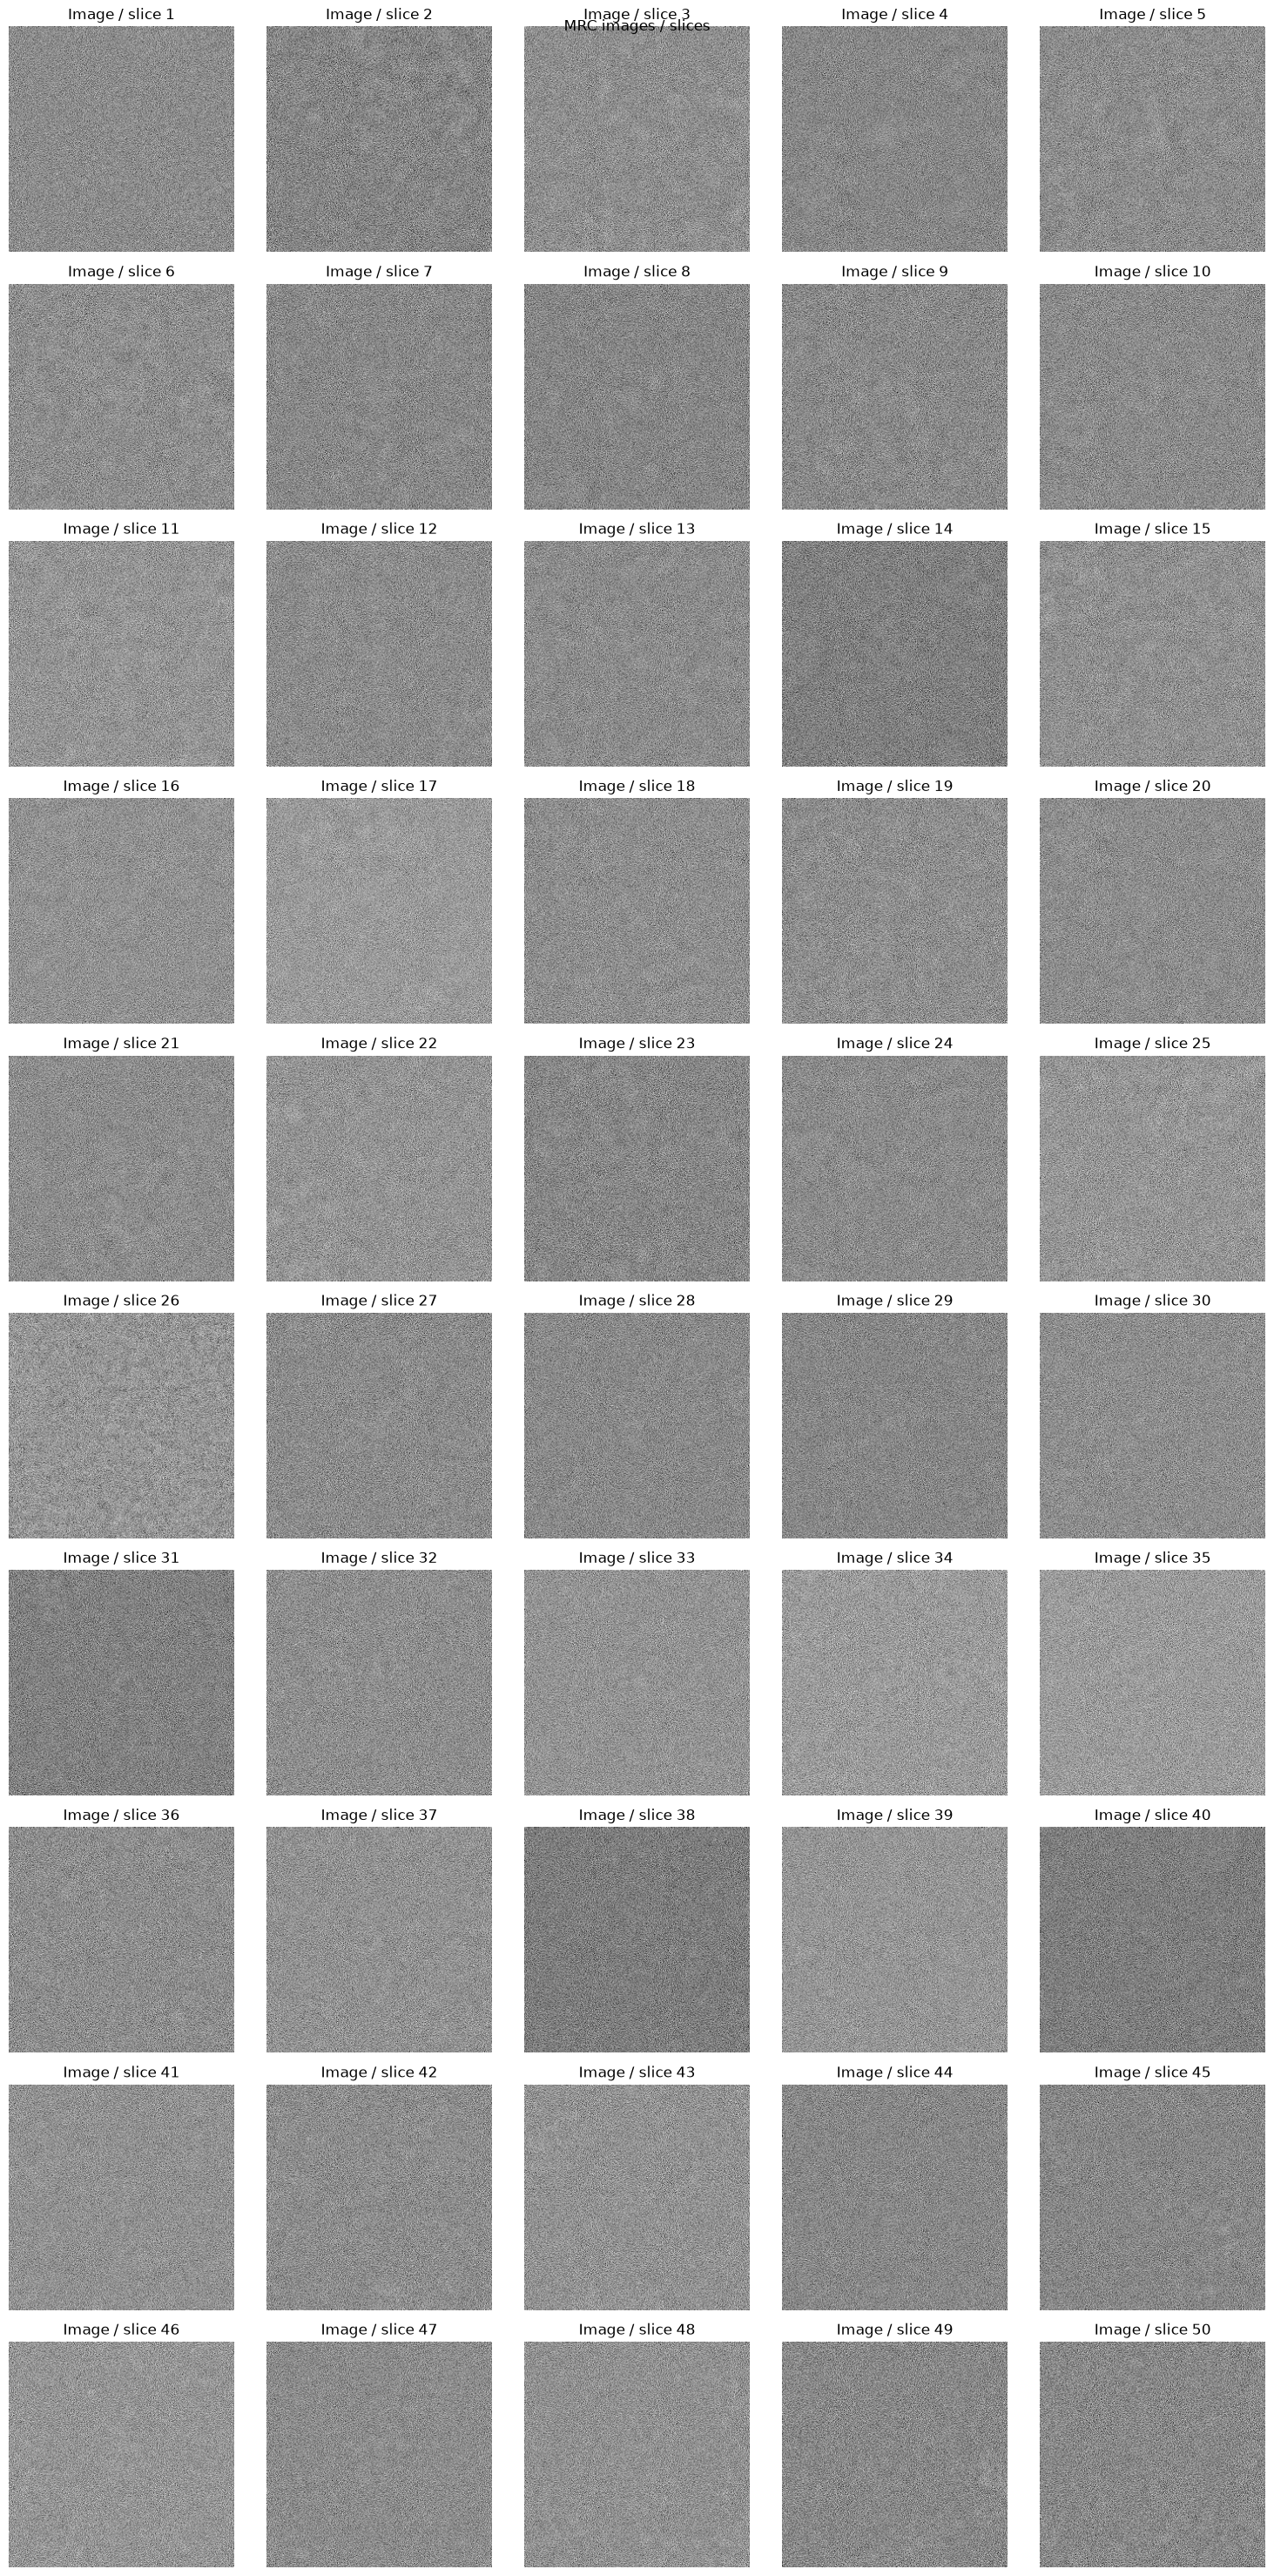

In [9]:
# Preparation: change this path if you want to use a different stack.
large_mrc_path = (
    project_root / "LatentSpace_data" / "tam_dimer_tetramer" / "batch_0_restacked.mrc"
)
number_of_images = 50

# Execution: only these images are copied into memory.
subset_data = read_first_mrc_images(large_mrc_path, count=number_of_images)
print(f"Shape: {subset_data.shape}")
print(f"Data type: {subset_data.dtype}")

# Preview 10 to keep the notebook output small. Use subset_data to display all 50.
display_mrc(subset_data[:50])


## 5. Select 50 particles using STAR metadata and display their image names

The STAR file contains optics settings and a particle table. `rlnImageName` has the form `049669@J598/restack/batch_0_restacked.mrc`: image 49,669 in that stack (one-based indexing). STAR row order is not stack order.

This section selects the first 50 matching **STAR rows**, loads their referenced images, and retains the matching metadata in `selected_particles`. These can differ from the first 50 stack images loaded in section 4. The old exported stack path is explicitly mapped to your local file below. Only selected images are copied into RAM.


In [10]:
# Preparation: install in this notebook's kernel if necessary.
# %pip install starfile
import starfile

star_path = project_root / "LatentSpace_data" / "tam_dimer_tetramer" / "J599_split_0_exported.star"
# Map the original exported path to the corresponding local copy.
stack_paths = {
    "J598/restack/batch_0_restacked.mrc": (
        project_root / "LatentSpace_data" / "tam_dimer_tetramer" / "batch_0_restacked.mrc"
    )
}


In [14]:
def read_star_images(star_path, stack_paths, count=50):
    """Load selected STAR particles and return their matching metadata."""
    if count < 1:
        raise ValueError("count must be at least 1")
    tables = starfile.read(star_path, always_dict=True)
    particles = tables["particles"]
    references = particles["rlnImageName"].str.split("@", n=1, expand=True)
    selected = particles.loc[references[1].isin(stack_paths)].head(count).copy()
    if selected.empty:
        raise ValueError("No STAR image references match stack_paths")

    selected_refs = selected["rlnImageName"].str.split("@", n=1, expand=True)
    images = [None] * len(selected)
    # Open each stack once and preserve the selected STAR row order.
    for exported_path in selected_refs[1].unique():
        positions = np.flatnonzero((selected_refs[1] == exported_path).to_numpy())
        with mrcfile.mmap(str(stack_paths[exported_path]), mode="r") as mrc:
            if mrc.data.ndim != 3:
                raise ValueError("Expected a stack of 2D images")
            for position in positions:
                index = int(selected_refs.iloc[position, 0]) - 1
                if not 0 <= index < mrc.data.shape[0]:
                    raise IndexError(f"Invalid image reference: {selected.iloc[position]['rlnImageName']}")
                images[position] = mrc.data[index].copy()
    return np.stack(images), selected.reset_index(drop=True)


Loaded 50 images; 6.2 MiB


,rlnImageName,rlnAngleRot,rlnAngleTilt,rlnAnglePsi,rlnOriginXAngst,rlnOriginYAngst,rlnDefocusU,rlnDefocusV,rlnDefocusAngle,rlnPhaseShift,rlnCtfBfactor,rlnOpticsGroup,rlnRandomSubset,rlnClassNumber
0,049669@J598/restack/batch_0_restacked.mrc,163.381989,119.030304,-7.056242,-20.544062,13.995312,17018.250000,16842.916016,-46.721073,0.0,0.0,3,1,1
1,049670@J598/restack/batch_0_restacked.mrc,-150.340240,129.391602,-82.390015,-2.904687,-17.269688,16970.322266,16794.988281,-46.721073,0.0,0.0,3,2,1
2,049671@J598/restack/batch_0_restacked.mrc,-29.071199,82.066505,-72.441399,-3.115937,-12.199687,17110.322266,16934.988281,-46.721073,0.0,0.0,3,1,1
3,049672@J598/restack/batch_0_restacked.mrc,-134.434067,132.910873,108.498589,10.192812,21.600311,16947.931641,16772.597656,-46.721073,0.0,0.0,3,1,1
4,013685@J598/restack/batch_0_restacked.mrc,121.144028,128.762985,98.272430,12.516562,16.847187,17329.041016,17214.406250,-63.691334,0.0,0.0,3,1,1


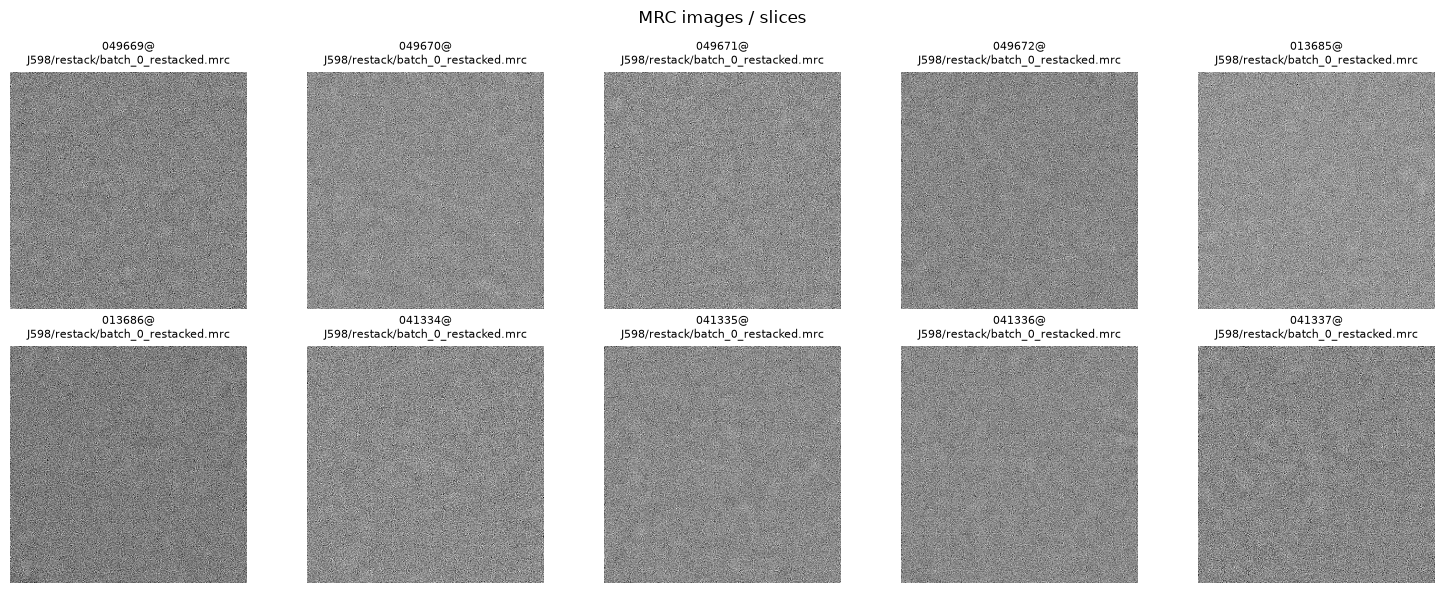

In [16]:
# Execution: select 50 metadata rows and load their referenced images.
star_data, selected_particles = read_star_images(star_path, stack_paths, count=50)
image_names = selected_particles["rlnImageName"].tolist()
print(f"Loaded {len(star_data)} images; {star_data.nbytes / 1024**2:.1f} MiB")
display(selected_particles.head())

# Preview 10. Change preview_count to 50 to display the whole selection.
preview_count = 10
display_mrc(star_data[:preview_count], image_names=image_names[:preview_count])


# Image Processing